# Compare NGC 4151 fits: parallel chunks and no chunks

Fit the **same DC4 mock data and NGC 4151 GTI twice**, using the two generated 71-source YAML catalogs. Each fit gets a lightcurve-weighted response calculated with the normalization convention of its own catalog. The injected NGC 4151 spectrum is CPL + PL; both fits use a CPL-only source model with free `K`, `index`, and `xc`, plus a free instrumental-background rate. Every other source is fixed.

The checked-in response JSON describes the parallel-chunk catalog. This notebook verifies that the generated parallel YAML matches the checked-in catalog, then derives the no-chunk response recipe **in memory** from the same hashed lightcurves. It checks that the changed YAML amplitudes equal the changed full-observation lightcurve means. Neither YAML nor the checked-in response JSON is edited.

Run top to bottom in the `cosipy312` kernel. The cached NSIDE-8 extended response is about 13 GiB in memory. The two fits run sequentially and reuse the same data, GTI, detector response, and extended response. The comparison includes a fit table, covariance-propagated 68% spectral uncertainty bands, and observed-count residuals. The observed counts and input background template are the same for both methods.


## 1. Imports and catalog helpers

These helpers follow `NGC4151_DC4_Spectral_Fit_Source_Cat_lightcurve.ipynb`. The catalog loader changes external file paths only in memory.


In [16]:
from pathlib import Path
from copy import deepcopy
import sys
import gc

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits


In [17]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [18]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    if recipe['selection'] != 'full':
        raise ValueError('This tutorial requires the full-observation catalog')
    return model, recipe, template_rows


In [19]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


## 2. Paths and matching temporal recipes

Set the data paths here if your checkout is elsewhere. The original response JSON supplies source/component names and SHA-256 hashes. For the no-chunk case we change every variable lightcurve to one global MEGAlib normalization interval and recompute its full-observation mean. The catalog-to-recipe amplitude checks below catch a mismatched YAML.


In [20]:
# Locate this tutorial from its directory or from a cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "source_catalog_DC4_all_71files_full_elapsed_lightcurve_parallel_chunks_generated.yaml").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from the cosipy checkout or set notebook_dir explicitly")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"

dc4_files_root = Path.home() / (
    "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files"
)
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / (
    "Mock_Data/Mock_Data_Cut/mock_with_updated_NGC4151_FluxNTH_0p30_time_cut.hdf5"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck_"
    "NGC4151_60deg_fov_cut.hdf5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / (
    "source_catalog_DC4_all_71files_full_elapsed_lightcurve_parallel_chunks_generated.yaml"
)
no_chunks_catalog_path = notebook_dir / (
    "source_catalog_DC4_all_71files_full_elapsed_lightcurve_no_chunks_generated.yaml"
)
reference_catalog_path = notebook_dir / (
    "source_catalog_DC4_all_71files_full_elapsed_lightcurve_response_norm.yaml"
)
reference_recipe_path = reference_catalog_path.with_suffix(".response.json")
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
overwrite_spatial_templates = False
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)

# Scale data and response exposure together for a repeated-observation study.
exposure_multiplier = 1
if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be finite and positive")
for path in (mock_data_path, background_path, orientation_path, response_path,
             agn_config, parallel_catalog_path, no_chunks_catalog_path,
             reference_catalog_path, reference_recipe_path, source_library):
    if not path.exists():
        raise FileNotFoundError(f"Missing input: {path}")
if parallel_catalog_path.read_bytes() != reference_catalog_path.read_bytes():
    raise ValueError("Generated parallel YAML has changed relative to the recipe's reference catalog")
print("Parallel YAML matches the checked-in response recipe's catalog.")


Parallel YAML matches the checked-in response recipe's catalog.


In [21]:
# Relocate all source assets and spatial templates for the current machine.
base_recipe = json.loads(reference_recipe_path.read_text())

def recipe_for_catalog(catalog_path):
    recipe = deepcopy(base_recipe)
    recipe["catalog"] = str(catalog_path.resolve())
    return recipe

parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, recipe_for_catalog(parallel_catalog_path),
    source_library, spatial_template_directory, orientation_path,
    response_path, agn_config, overwrite=overwrite_spatial_templates,
)
no_chunks_model, no_chunks_recipe, _ = prepare_catalog(
    no_chunks_catalog_path, recipe_for_catalog(no_chunks_catalog_path),
    source_library, spatial_template_directory, orientation_path,
    response_path, agn_config, overwrite=overwrite_spatial_templates,
)
sc_orientation_full = SpacecraftHistory.open(orientation_path)
reference_start = float(sc_orientation_full.obstime[0].unix)
reference_stop = float(sc_orientation_full.obstime[-1].unix)
reference_duration = reference_stop - reference_start
if reference_duration <= 0:
    raise ValueError("The full orientation needs positive elapsed time")

# The parallel recipe is reused unchanged. Change only the no-chunk recipe.
for row in no_chunks_recipe["components"]:
    if not row["lightcurve"]:
        continue
    row["normalization mode"] = "global_megalib"
    row["simulation bins"] = 1
    profile = LightcurveProfile.from_dat(
        row["lightcurve"], expected_sha256=row["lightcurve sha256"],
        repeating=row["repeating"], mode="global_megalib", bins=1,
    )
    emission_seconds = float(profile.integral([reference_start], [reference_stop])[0])
    row["effective emission seconds"] = emission_seconds
    row["time factor"] = emission_seconds / reference_duration
    row["applied factor"] = max(row["time factor"], 1e-30)
no_chunks_recipe["normalization_assumptions"] = (
    "All variable lightcurves use one global MEGAlib normalization interval."
)

method_models = {"parallel chunks": parallel_model, "no chunks": no_chunks_model}
method_recipes = {"parallel chunks": parallel_recipe, "no chunks": no_chunks_recipe}
for method, model in method_models.items():
    assert len(model.sources) == 71 and "ngc4151" in model.point_sources
    assert not model.free_parameters
    print(f"{method}: {len(model.point_sources)} point + {len(model.extended_sources)} extended sources")
display(pd.DataFrame(template_status))


parallel chunks: 52 point + 19 extended sources
no chunks: 52 point + 19 extended sources


,source,status,file
0,positrons_26al_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
1,positrons_26al_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
2,positrons_44ti_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
3,positrons_44ti_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
4,narrow_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
5,broad_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
6,vela_snr_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
7,al26_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
8,fe60_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
9,positrons_thin_disk_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...


In [22]:
def component_normalizations(source, label):
    """Find the spectral amplitude parameters affected by one recipe row."""
    components = (source.components.values() if label == "all"
                  else [source.components[component_name(source, label)]])
    values = {}
    for component in components:
        parameters = list(component.shape.parameters.values())
        amplitudes = [p for p in parameters if p.is_normalization]
        if not amplitudes:
            # astromodels does not flag a Gaussian line's F as normalization.
            amplitudes = [p for p in parameters
                          if p.name.split("_", 1)[0] in {"F", "K", "k"}]
        if not amplitudes:
            raise ValueError(f"No amplitude in {source.name}/{component.name}")
        for parameter in amplitudes:
            values[(component.name, parameter.name)] = float(parameter.value)
    return values

# Confirm that the two catalog amplitudes carry exactly their respective
# full-observation means. This is essential before response folding.
parallel_rows = {(r["source"], r["component"]): r for r in parallel_recipe["components"]}
checked = 0
for row in no_chunks_recipe["components"]:
    if not row["lightcurve"]:
        continue
    key = (row["source"], row["component"])
    reference = parallel_rows[key]
    parallel_values = component_normalizations(parallel_model.sources[row["source"]], row["component"])
    no_chunks_values = component_normalizations(no_chunks_model.sources[row["source"]], row["component"])
    if parallel_values.keys() != no_chunks_values.keys():
        raise ValueError(f"Component amplitudes differ structurally for {key}")
    expected_ratio = row["applied factor"] / reference["applied factor"]
    for parameter_key, parallel_value in parallel_values.items():
        observed_ratio = no_chunks_values[parameter_key] / parallel_value
        if not np.isclose(observed_ratio, expected_ratio, rtol=1e-8, atol=0):
            raise ValueError(f"Catalog/recipe amplitude mismatch: {key}/{parameter_key}")
        checked += 1
print(f"Verified {checked} variable-component amplitude ratios against both temporal recipes.")


Verified 37 variable-component amplitude ratios against both temporal recipes.


## 3. Load the common GTI, data, and detector response

Both fits use identical observed counts, background template, orientation cut, and response binning. Only the catalog and its source-specific temporal response change.


In [23]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings belong to the selected data, not to the full catalog.
max_offaxis = 60.0 * u.deg
earth_occ = True

sc_orientation_full = SpacecraftHistory.open(orientation_path)
source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")

Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [24]:
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config,
    already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config,
    already_selected=background_already_gti_selected,
)
if total_bkg.axes != data_hist.axes:
    raise ValueError("Mock data and background must have identical Em/Phi/PsiChi axes")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
total_bkg += sys.float_info.min
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))

Initial instrumental-background rate: 25.5719 Hz


In [25]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in method_models.values():
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


Using unpolarized folding for: ['crab.bridge', 'crab.nebula', 'crab.peak1', 'crab.peak2', 'grb_bn080802386_flux150.bn080802386', 'grb_bn090424592.bn090424592', 'grb_bn100612726.bn100612726', 'grb_bn110605183.bn110605183', 'grb_bn131122490.bn131122490', 'grb_bn140329295.bn140329295', 'grb_bn161004964.bn161004964', 'grb_bn170405777.bn170405777', 'grb_bn180504136.bn180504136', 'grb_bn180703876.bn180703876', 'mgf_051103.mgf051103', 'mgf_070201.mgf070201', 'mgf_070222.mgf070222', 'mgf_180128a.mgf180128a', 'mgf_200415a.mgf200415a', 'mgf_231115a.mgf231115a']
Loading cached GTI extended response (about 13 GiB)...
Shared ordinary responses are ready.


## 4. Run both fits sequentially

We rebuild only the source-specific lightcurve responses for each method. Each fit gets a fresh background object because its constructor normalizes the supplied histogram in place when `copy=False`; here `copy=True` preserves the common input. The fitted source model is CPL-only in both cases.


In [26]:
D = 0.30  # Nonthermal injected fraction used by the existing fit tutorial.
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = D * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj = spectrum_inj_cpl + spectrum_inj_tail
energy = np.geomspace(200 * u.keV, 5 * u.MeV).to_value(u.keV)
injected_flux = np.asarray([spectrum_inj.evaluate_at(e) for e in energy])
binned_energy_edges = data_hist.axes["Em"].edges.to_value(u.keV)
binned_energy = 0.5 * (binned_energy_edges[1:] + binned_energy_edges[:-1])
observed_counts = np.asarray(data_hist.project("Em").to_dense(copy=False).contents, dtype=float).copy()

def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    shape.index.min_value, shape.index.max_value = -10., 10.
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("The two fits must free only NGC 4151 K, index and xc")
    return model


In [27]:
def fit_one_method(method):
    """Run one independent fit and keep only small numerical outputs."""
    model = make_fit_model(method_models[method])
    recipe = method_recipes[method]
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    source_specific, temporal_diagnostics = make_temporal_responses(
        model, recipe, sc_orientation_cut, source_gti, data,
        instrument_response, dr, exposure_multiplier=exposure_multiplier,
        full_history=sc_orientation_full,
    )
    response = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=source_specific,
    )
    likelihood = PoissonLikelihood(data, response, background)
    plugin = ThreeMLPluginInterface("cosi", likelihood, response, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial,
        min_value=0.0, max_value=50.0,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    joint.fit()
    joint.restore_best_fit()
    # This synchronizes the restored background parameter in the plugin.
    log_likelihood = float(plugin.get_log_like())
    results = joint.results
    fit_shape = results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw

    # Propagate the joint fit covariance of K, index, and xc. threeML keeps
    # their correlations when drawing the variates for this CPL flux.
    def ngc4151_flux(energy_keV, K, index, xc):
        return K * (energy_keV / fit_shape.piv.value)**index * np.exp(-energy_keV / xc)

    flux_variates = results.propagate(
        ngc4151_flux,
        K=results.get_variates(fit_shape.K.path),
        index=results.get_variates(fit_shape.index.path),
        xc=results.get_variates(fit_shape.xc.path),
    )
    flux_low = np.empty_like(energy)
    flux_high = np.empty_like(energy)
    for i, energy_keV in enumerate(energy):
        flux_low[i], flux_high[i] = flux_variates(energy_keV).equal_tail_interval(cl=0.68)

    source_counts = np.asarray(
        response.expectation().project("Em").to_dense(copy=False).contents,
        dtype=float,
    ).copy()
    background_counts = np.asarray(
        background.expectation(copy=True).project("Em").to_dense(copy=False).contents,
        dtype=float,
    ).copy()
    summary = {
        "method": method,
        "K": float(fit_shape.K.value),
        "index": float(fit_shape.index.value),
        "xc (keV)": float(fit_shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "source counts": source_counts,
        "background counts": background_counts,
        "model counts": source_counts + background_counts,
        "fit flux": np.asarray([fit_shape.evaluate_at(e) for e in energy]),
        "fit flux low 68": flux_low,
        "fit flux high 68": flux_high,
        "temporal diagnostics": pd.DataFrame(temporal_diagnostics),
    }
    print(f"Completed {method}; log likelihood = {log_likelihood:.6g}")
    print(joint.results.display())
    return summary

fit_outputs = {}
for method in ("parallel chunks", "no chunks"):
    print(f"\nRunning {method} fit...")
    fit_outputs[method] = fit_one_method(method)
    gc.collect()  # Release method-specific response and likelihood caches.



Running parallel chunks fit...


16:08:39 INFO      set the minimizer to minuit                                             ]8;id=70756;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=110343;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

16:08:43 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=100266;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=420878;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=935359;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=89940;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\


WARNING IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.



...

Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi,-118225649.30641367
total,-118225649.30641367


Values of statistical measures:

,statistical measures
AIC,-236451290.6126537
BIC,-236451249.2225385


None


## 5. Compare fit parameters and observed counts

The likelihood values are directly comparable because both fits use the same data, bins, free parameters, and background model. A higher log likelihood is a better fit to these counts. The colored spectral bands are 68% equal-tail intervals propagated from each fit covariance, including correlations among the CPL parameters. The energy-projected count residuals are a visualization; the optimizer uses the full Em/Phi/PsiChi likelihood.


In [28]:
fit_table = pd.DataFrame([
    {key: output[key] for key in (
        "method", "K", "index", "xc (keV)", "background (Hz)", "log likelihood"
    )}
    for output in fit_outputs.values()
]).set_index("method")
fit_table["delta log likelihood vs parallel"] = (
    fit_table["log likelihood"] - fit_table.loc["parallel chunks", "log likelihood"]
)
for method, output in fit_outputs.items():
    counts = output["model counts"]
    fit_table.loc[method, "Em count residual RMS"] = np.sqrt(np.mean(
        ((counts - observed_counts) / np.sqrt(np.maximum(observed_counts, 1.)))**2
    ))
display(fit_table)


,K,index,xc (keV),background (Hz),log likelihood,delta log likelihood vs parallel,Em count residual RMS
method,,,,,,,
parallel chunks,6.866247e-06,0.032819,196.312027,25.602284,1.182288e+08,0.000000,3.511191
no chunks,1.082222e-08,2.706679,705.305752,25.083026,1.182256e+08,-3137.758083,12.905051


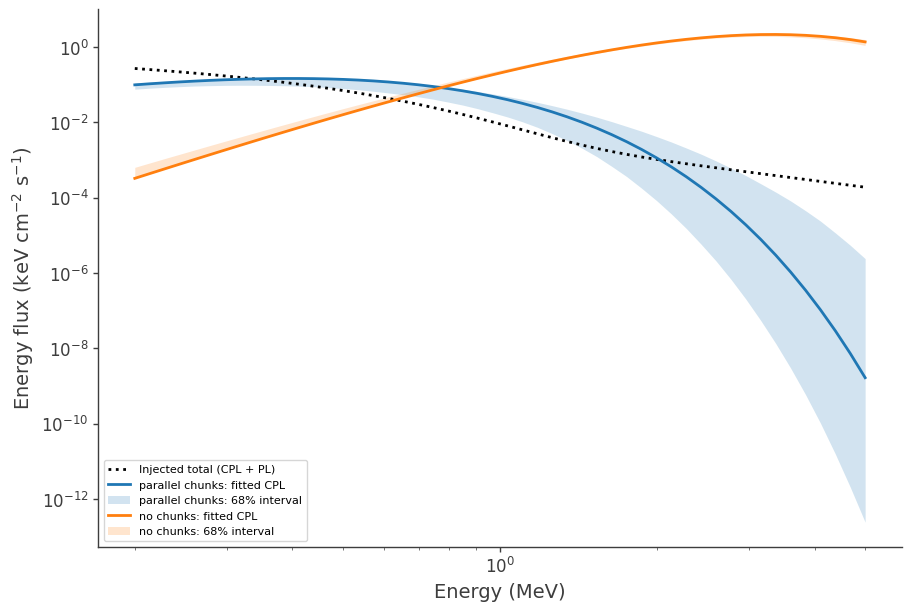

In [29]:
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.plot(energy / 1000, energy**2 * injected_flux, color="black", ls=":",
        lw=2, label="Injected total (CPL + PL)")
colors = {"parallel chunks": "tab:blue", "no chunks": "tab:orange"}
for method, output in fit_outputs.items():
    ax.plot(energy / 1000, energy**2 * output["fit flux"],
            color=colors[method], lw=2, label=f"{method}: fitted CPL")
    # Mask nonpositive interval endpoints on the log axis, if any covariance
    # draws produce them; retain the numerical intervals in fit_outputs.
    lower = np.where(output["fit flux low 68"] > 0,
                     energy**2 * output["fit flux low 68"], np.nan)
    upper = np.where(output["fit flux high 68"] > 0,
                     energy**2 * output["fit flux high 68"], np.nan)
    ax.fill_between(energy / 1000, lower, upper, color=colors[method],
                    alpha=0.20, linewidth=0, label=f"{method}: 68% interval")
ax.set(xscale="log", yscale="log", xlabel="Energy (MeV)",
       ylabel=r"Energy flux (keV cm$^{-2}$ s$^{-1}$)")
ax.legend()
plt.show()


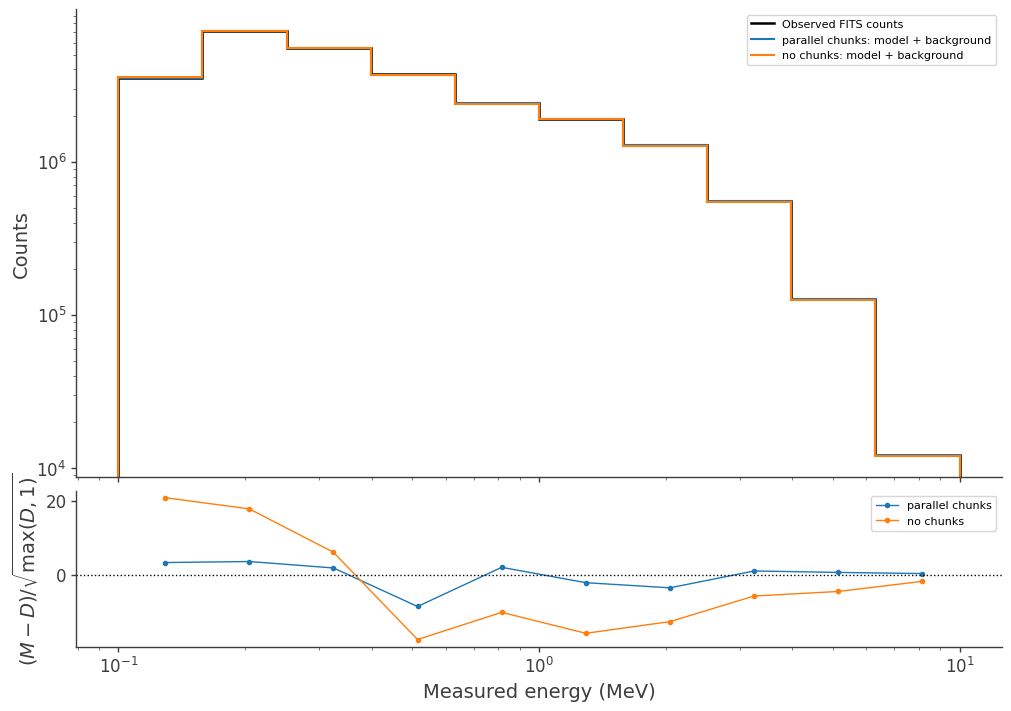

In [30]:
fig, (ax, residual_ax) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True,
)
ax.stairs(observed_counts, binned_energy_edges / 1000,
          color="black", lw=1.8, label="Observed FITS counts")
for method, output in fit_outputs.items():
    model_counts = output["model counts"]
    ax.stairs(model_counts, binned_energy_edges / 1000,
              color=colors[method], lw=1.5, label=f"{method}: model + background")
    residual_ax.plot(
        binned_energy / 1000,
        (model_counts - observed_counts) / np.sqrt(np.maximum(observed_counts, 1.)),
        marker="o", ms=3, lw=1, color=colors[method], label=method,
    )
ax.set(yscale="log", ylabel="Counts")
ax.legend()
residual_ax.axhline(0, color="black", ls=":", lw=1)
residual_ax.set(xscale="log", xlabel="Measured energy (MeV)",
                ylabel=r"$(M-D)/\sqrt{\max(D,1)}$")
residual_ax.legend()
plt.show()
